# 00 · Environment check

In [1]:
import platform
import numpy as np, torch, mujoco, mujoco_menagerie as mm, matplotlib.pyplot as plt
from vlacourse import TableTop, show_images

In [2]:
print("python  ", platform.python_version())
print("mujoco  ", mujoco.__version__)
print("torch   ", torch.__version__, "| cuda:", torch.cuda.is_available())
if torch.cuda.is_available():
    p = torch.cuda.get_device_properties(0)
    print("gpu     ", p.name, f"{p.total_memory/2**30:.1f} GB")

python   3.11.18
mujoco   4.0.0
torch    2.6.0+cu124 | cuda: True
gpu      NVIDIA RTX 500 Ada Generation Laptop GPU 4.0 GB


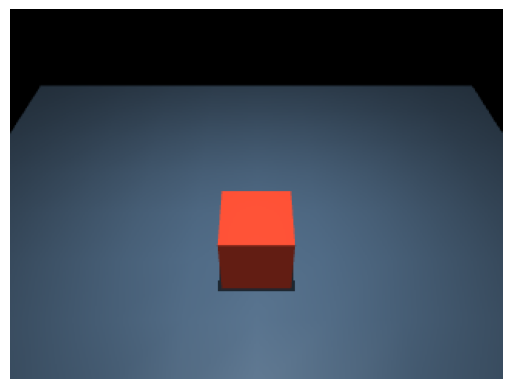

In [3]:
xml = """
<mujoco>
  <worldbody>
    <light pos="0 0 2"/>
    <geom type="plane" size="1 1 .1" rgba=".3 .4 .5 1"/>
    <body pos="0 0 .5"><freejoint/><geom type="box" size=".1 .1 .1" rgba="1 .3 .2 1"/></body>
  </worldbody>
</mujoco>"""
model = mujoco.MjModel.from_xml_string(xml)
data = mujoco.MjData(model)
mujoco.mj_step(model, data, 500)
with mujoco.Renderer(model, 240, 320) as r:
    r.update_scene(data)
    plt.imshow(r.render()); plt.axis("off"); plt.show()

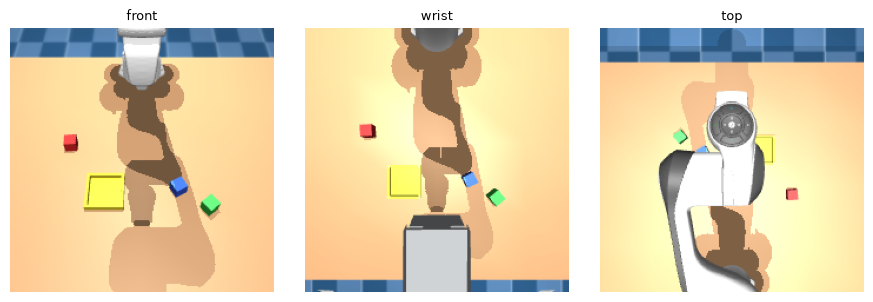

stack the green cube on the blue cube [ 0.554 -0.     0.521  0.     0.707  0.707  0.     0.08 ]


In [4]:
env = TableTop(seed=0, cameras=("front", "wrist", "top"))
obs = env.reset(seed=0)
show_images(list(obs["images"].values()), list(obs["images"]))
print(obs["instruction"], obs["state"].round(3))

In [5]:
COURSE_ROBOTS = ["franka_emika_panda", "franka_fr3", "universal_robots_ur5e", "robotiq_2f85", "robotstudio_so101",
                 "trs_so_arm100", "aloha", "unitree_go2", "unitree_g1", "shadow_hand", "leap_hand", "kinova_gen3",
                 "realsense_d435i"]
for name in COURSE_ROBOTS:
    for attempt in range(3):
        try:
            m = mm.load(name)
            print(f"{name:24s} ok  nq={m.nq:3d} nu={m.nu:3d}")
            break
        except Exception as e:
            if attempt == 2:
                print(f"{name:24s} FAILED: {e}")

franka_emika_panda       ok  nq=  9 nu=  8


franka_fr3               ok  nq=  7 nu=  7


universal_robots_ur5e    ok  nq=  6 nu=  6


robotiq_2f85             ok  nq= 15 nu=  1
robotstudio_so101        ok  nq=  6 nu=  6


trs_so_arm100            ok  nq=  6 nu=  6


aloha                    ok  nq= 16 nu= 14


unitree_go2              ok  nq= 19 nu= 12


unitree_g1               ok  nq= 36 nu= 29
shadow_hand              ok  nq= 31 nu= 20


leap_hand                ok  nq= 16 nu= 16
kinova_gen3              ok  nq=  7 nu=  7


realsense_d435i          ok  nq=  0 nu=  0
